In [29]:
import os
import sys
sys.path.append(r"C:\Users\acostamendoza\projects\distance-project")
from path_setup import setup_project_path
setup_project_path()
from src.utils import create_new_result_dir
from src.LinearExperiment import LinearDevice, LinearPlots, LinearSummaries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from suite2p.extraction import dcnv
from src.ActivityPipelines import ActivityLoader
from scipy.ndimage import gaussian_filter1d
import pickle
import os

%load_ext autoreload
%autoreload 2

colors = ['orange', '#35b779', '#31688e', '#440154', 'gray']
mouse_name = 'SAM033'
record_date = '250616'
experiment_name = 'mapping_V'

if experiment_name == 'history':
    conditions = [
        {'history': False, 'monocular': None, 'title':'No-History'},
        {'history': True, 'monocular': None, 'title':'History'}
    ]
elif 'linear-device' in experiment_name:
    conditions = [
        {'history': False, 'monocular': True, 'title':'Monocular - No History'},
        {'history': True, 'monocular': True, 'title':'Monocular - History'},
        {'history': False, 'monocular': False, 'title':'Binocular - No History'},
        {'history': True, 'monocular': False, 'title':'Binocular - History'}
    ]
elif 'binocular' in experiment_name:
    conditions = [
        {'history': None, 'monocular': True, 'title':'Monocular - No History'},
        {'history': None, 'monocular': False, 'title':'Binocular - No History'},
    ]

elif 'mapping' in experiment_name:
    conditions = [
        {'history': None, 'monocular': False, 'title':'Binocular - No History'},
        {'history': None, 'monocular': None, 'title':'All Conditions'},
    ]
else:
    raise ValueError(f"Conditions not found for {experiment_name}")

data_dir = r'D:/data-distance-coding-project/processed-data/{record_date}_{mouse_name}_{experiment_name}/'.format(record_date=record_date, mouse_name=mouse_name, experiment_name=experiment_name)

if not os.path.exists(data_dir):
    raise FileNotFoundError(f"The directory {data_dir} does not exist.")
else:
    print(f"The directory {data_dir} exists.")

suite2p_dir = r'D:\data-distance-coding-project\processed-data\{record_date}_{mouse_name}_{experiment_name}\suite2p'.format(record_date=record_date, mouse_name=mouse_name, experiment_name=experiment_name)

# see if L object exists in suite2p_dir and if it does import it
if os.path.exists(os.path.join(suite2p_dir, 'L.pkl')):
    print('Processing object found in suite2p_dir')
    with open(os.path.join(suite2p_dir, 'L.pkl'), 'rb') as f:
        L = pickle.load(f)
else:
    print('Processing object not found in suite2p_dir, creating new object')
    L = LinearDevice(data_dir, response_mode='dFF')
    # Save L object
    with open(os.path.join(suite2p_dir, 'L.pkl'), 'wb') as f:
        pickle.dump(L, f)

# Check if stats file exists
stats_file = os.path.join(suite2p_dir, 'stats.pkl')
if os.path.exists(stats_file):
    print('Stats file found in suite2p_dir')
    with open(stats_file, 'rb') as f:
        stats = pickle.load(f)
else:
    # Compute stats if file doesn't exist
    print('Stats file not found in suite2p_dir, computing stats')
    stats = []
    for condition in conditions:
        stats.append(L.analyze_condition_stats(monocular=condition['monocular'], history=condition['history']))
    # Save stats
    with open(stats_file, 'wb') as f:
        pickle.dump(stats, f)

Summ = LinearSummaries(L, stats)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The directory D:/data-distance-coding-project/processed-data/250616_SAM033_mapping_V/ exists.
Processing object found in suite2p_dir
Stats file found in suite2p_dir


In [15]:
print(data_dir)

D:/data-distance-coding-project/processed-data/250609_SAM033_mapping_lateral/


In [22]:
stats_df = stats[0]

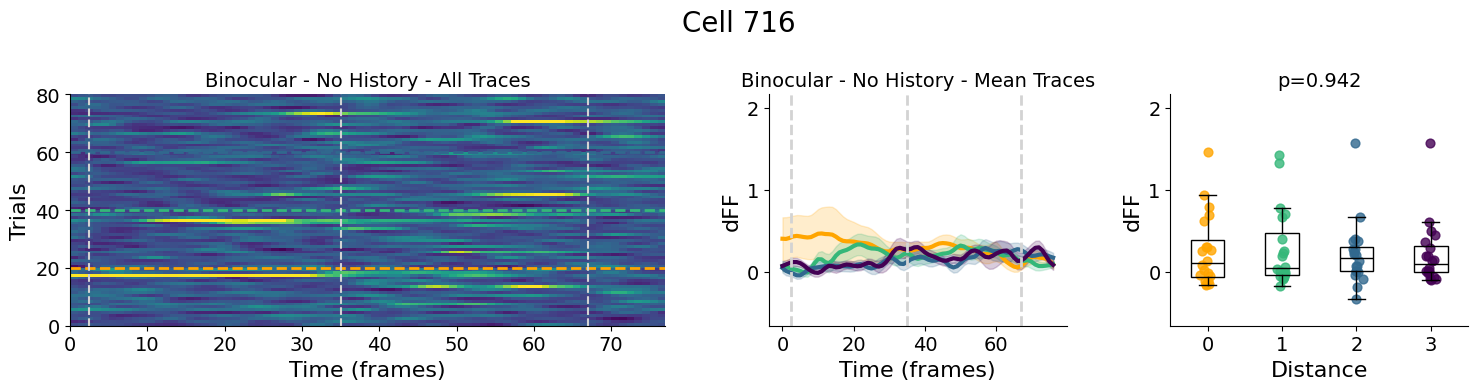

In [7]:
p_value, pref_distance, mod_strength, rf_values = L.analyze_cell_modulation(cell=716, monocular=False, history=False)
fig = LinearPlots(L).plot_all_traces_colormap_distances(cell=716, pre_time=3500, post_time=1000, conditions= [
                {'monocular': False, 'history': False, 'title': 'Binocular - No History'},
            ])

In [23]:
reliable_cell_ids = stats_df[stats_df['responsive'] == True]['cell_id'].values
# plot all cells
figure_path = create_new_result_dir(data_dir, 'dff_reliable')
for cell in reliable_cell_ids:
    fig = LinearPlots(L).plot_all_traces_colormap_distances(cell=cell, 
                                                      pre_time=3500, 
                                                      post_time=1000, 
                                                      conditions=[
                {'monocular': False, 'history': False, 'title': 'Binocular - No History'},
            ])
    fig.savefig(os.path.join(figure_path, f'cell_{cell}.png'))
    plt.close(fig)

Creating directory: dff_reliable


In [20]:
modulated_cell_ids = stats_df[stats_df['modulated'] == True]['cell_id'].values
# plot all cells
figure_path = create_new_result_dir(data_dir, 'dff_modulated')
for cell in modulated_cell_ids:
    fig = LinearPlots(L).plot_all_traces_colormap_distances(cell=cell, 
                                                      pre_time=3500, 
                                                      post_time=1000, 
                                                      conditions=[
                {'monocular': False, 'history': False, 'title': 'Binocular - No History'},
            ])
    fig.savefig(os.path.join(figure_path, f'cell_{cell}.png'))
    plt.close(fig)

Creating directory: dff_modulated


In [3]:
# Get cells ordered by reliability
ordered_cells = stats_df.sort_values('reliable', ascending=False)['cell_id'].values
figure_path = create_new_result_dir(data_dir, 'dff_reliable_binocular_no_history')

for cell in ordered_cells[:100]:
    fig = LinearPlots(L).plot_all_traces_colormap_distances(cell=cell, 
                                                      pre_time=3000, 
                                                      post_time=1000, 
                                                      conditions=conditions)
    fig.savefig(os.path.join(figure_path, f'cell_{cell}.png'))
    plt.close(fig)


NameError: name 'stats_df' is not defined

In [17]:
Summ = LinearSummaries(L, stats)

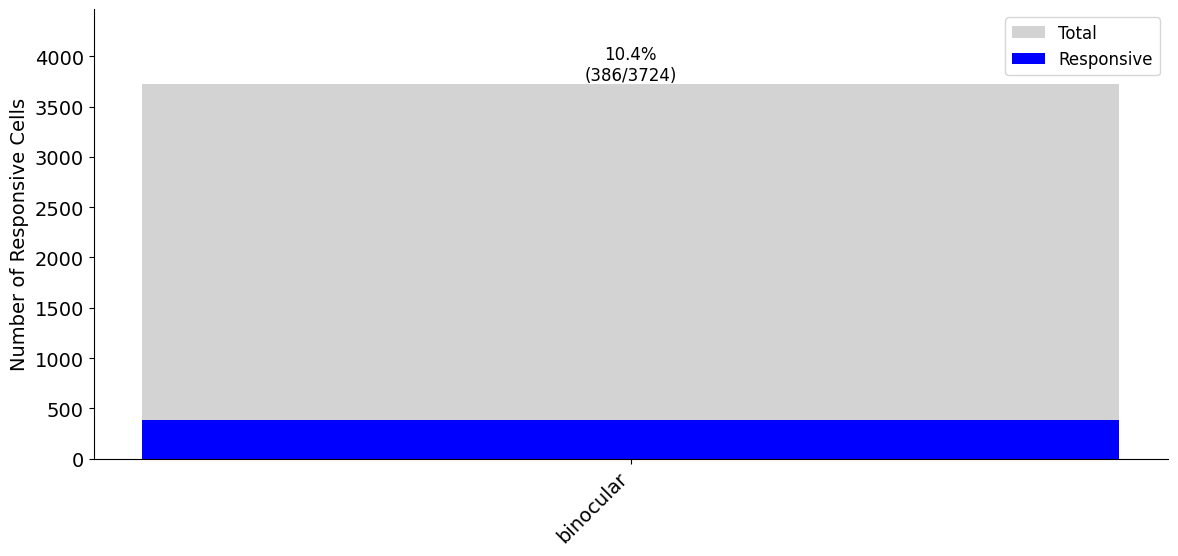

In [3]:
fig = Summ.plot_responsive_bars()
fig.savefig(os.path.join(data_dir, 'responsive_bars.png'))
plt.show()

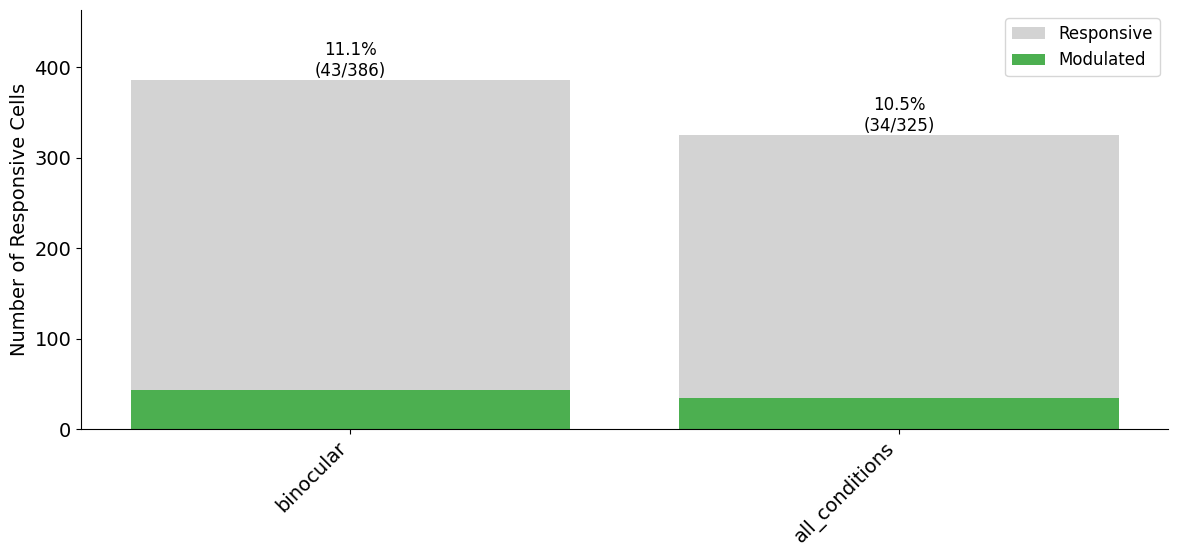

In [32]:
fig = Summ.plot_modulation_bars()
fig.savefig(os.path.join(data_dir, 'modulation_bars.png'))
plt.show()

binocular
all_conditions
non_modulated


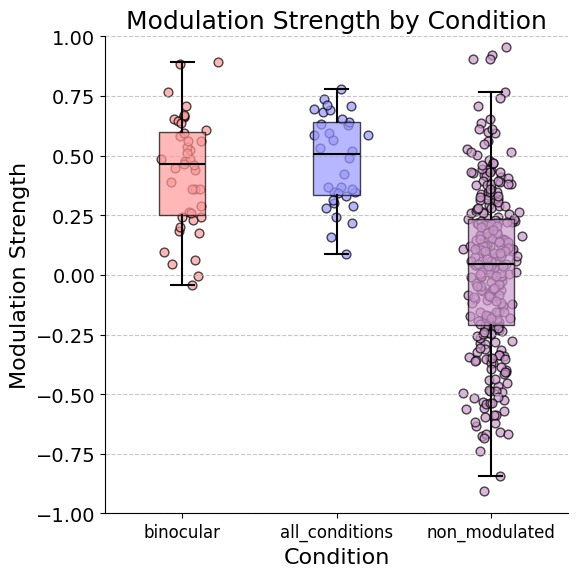

In [5]:
fig = Summ.plot_modulation_strength()
fig.savefig(os.path.join(data_dir, 'modulation_strength.png'))
plt.show()

C:\Users\acostamendoza\projects\distance-project\src\LinearExperiment.py:1517: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(conditions, fontsize=12)


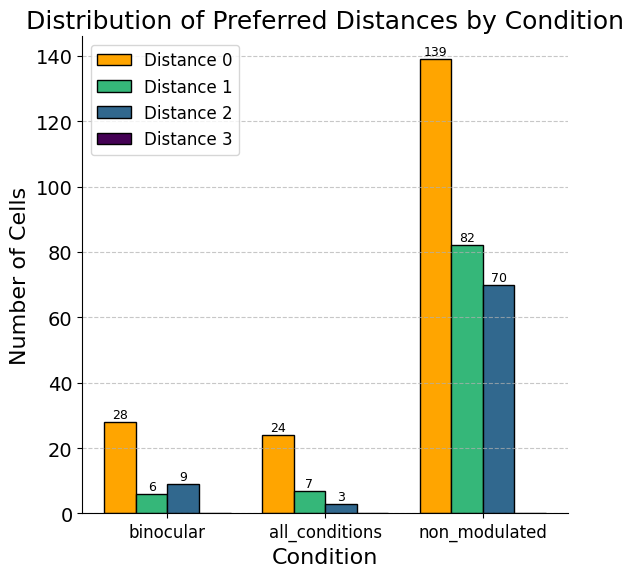

In [31]:
fig = Summ.plot_preferred_distance()
plt.show()

In [37]:
cell_id = 716
realibility = stats_df[stats_df['cell_id'] == cell_id]['reliable'].values[0]
print(realibility)

0.26398566


In [57]:
Summ.linear_stats

[      cell_id  responsive  reliable  modulated   modulated_p  mod_strength  \
 0           0       False  0.051889      False  5.674597e-07      0.839359   
 1           1       False  0.311154      False  2.623141e-03      0.591360   
 2           2       False  0.566109      False  5.791861e-06      0.743327   
 3           3       False  0.020027      False  1.347487e-04      0.911490   
 4           6       False  0.269462      False  5.166672e-01      0.144659   
 ...       ...         ...       ...        ...           ...           ...   
 2278     4442       False -0.179570      False  3.223258e-01      0.425173   
 2279     4446       False -0.419169      False  6.033455e-01     -0.397632   
 2280     4466       False -0.036580      False  1.329651e-01      0.190506   
 2281     4467       False  0.428730      False  3.282921e-02      0.981052   
 2282     4470       False  0.186849      False  3.989647e-01     -0.420514   
 
       pref_distance  condition  
 0              

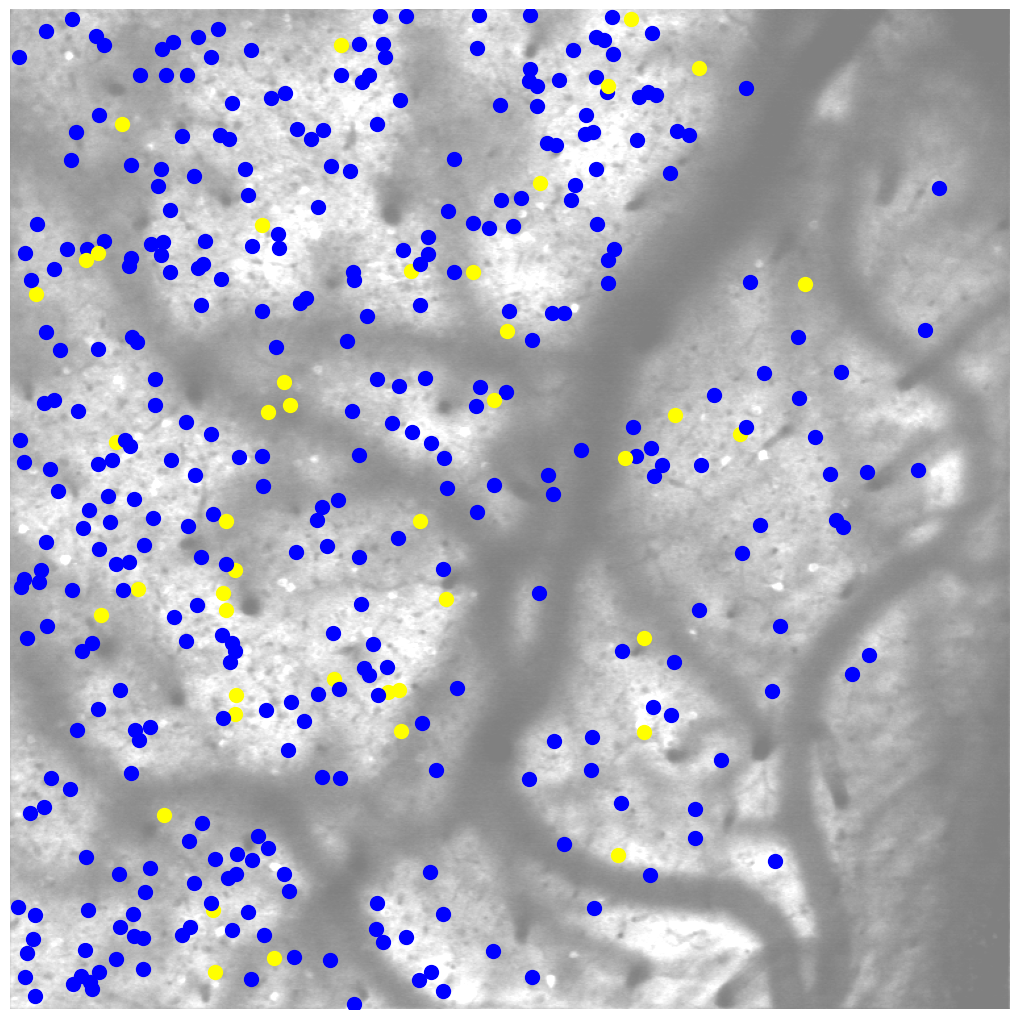

In [30]:
fig = Summ.plot_location_map('binocular')


In [34]:
fig = Summ.plot_preferred_distance()
fig.savefig(os.path.join(data_dir, 'preferred_distance.png'))
plt.show()

C:\Users\acostamendoza\projects\distance-project\src\LinearExperiment.py:1515: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(conditions, fontsize=12)


# Reliability

(48, 43)


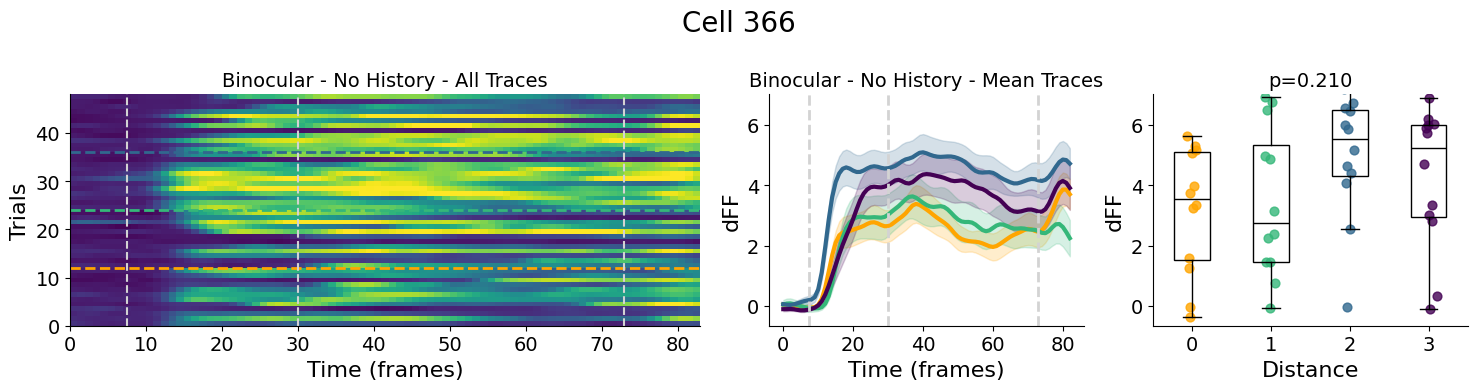

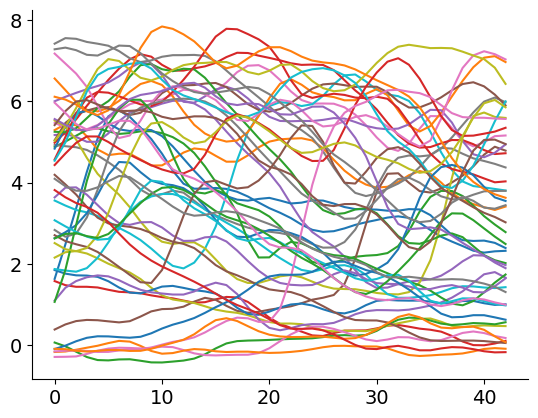

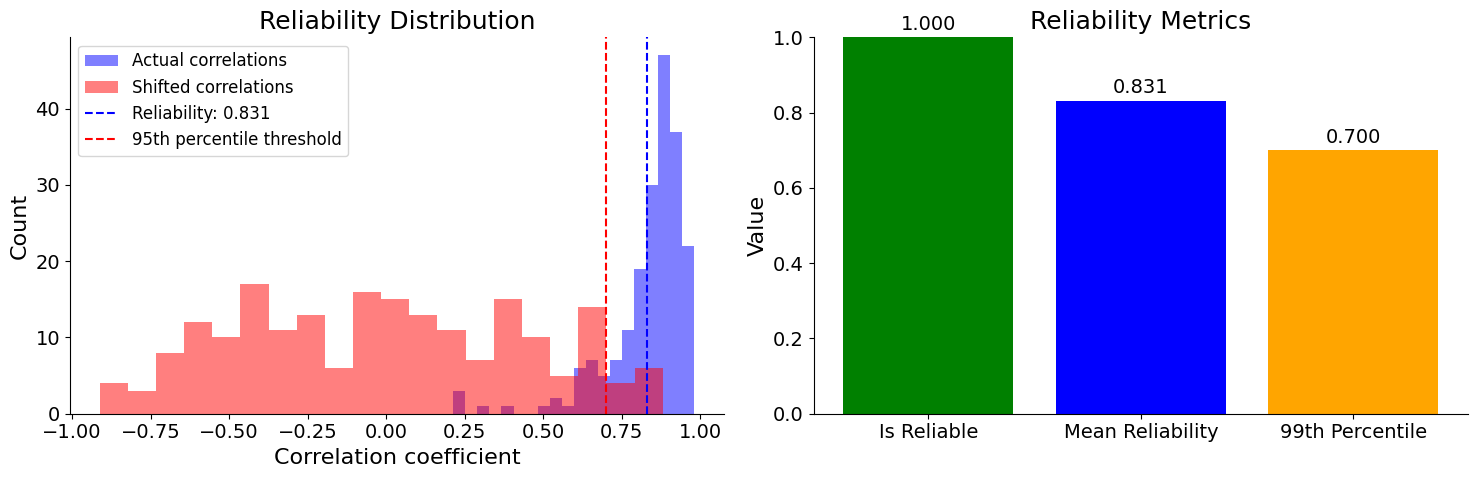

In [108]:
cell_id = 366
distance = None

fig = LinearPlots(L).plot_all_traces_colormap_distances(cell=cell_id, pre_time=3000, post_time=1000, conditions=[
                {'monocular': False, 'history': False, 'title': 'Binocular - No History'},
            ])

all_traces = L.get_all_traces(cell_id, monocular=False, history=False, distance=distance)
print(all_traces.shape)


plt.figure()
plt.plot(all_traces.T)

is_reliable, reliability, corr_shifted, corr = L.analyze_cell_reliability(cell_id, n_iterations=200, distance=distance, monocular=False, history=False)
# Create a figure to display reliability metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot reliability distribution
ax1.hist(corr, bins=20, alpha=0.5, label='Actual correlations', color='blue')
ax1.hist(corr_shifted, bins=20, alpha=0.5, label='Shifted correlations', color='red')
ax1.axvline(reliability, color='blue', linestyle='--', label=f'Reliability: {reliability:.3f}')
ax1.axvline(np.percentile(corr_shifted, 95), color='red', linestyle='--', 
            label='95th percentile threshold')
ax1.set_xlabel('Correlation coefficient')
ax1.set_ylabel('Count')
ax1.set_title('Reliability Distribution')
ax1.legend()

# Plot reliability metrics
metrics = ['Is Reliable', 'Mean Reliability', '99th Percentile']
values = [is_reliable, reliability, np.percentile(corr_shifted, 95)]
colors = ['green' if is_reliable else 'red', 'blue', 'orange']

ax2.bar(metrics, values, color=colors)
ax2.set_ylim(0, 1)
ax2.set_title('Reliability Metrics')
ax2.set_ylabel('Value')

# Add value labels on top of bars
for i, v in enumerate(values):
    ax2.text(i, v + 0.02, f'{v:.3f}', ha='center')

plt.tight_layout()
plt.show()


In [111]:
stats[2]

,cell_id,responsive,reliable,modulated,modulated_p,mod_strength,pref_distance,condition
0,0,False,-0.189162,False,0.273705,-0.739108,0,binocular_no_history
1,1,False,0.210270,False,0.510700,0.785159,3,binocular_no_history
2,2,False,0.104861,False,0.556859,-0.787627,2,binocular_no_history
3,3,False,0.797910,False,0.202348,-0.816206,0,binocular_no_history
4,4,False,-0.294883,False,0.881594,-0.802333,3,binocular_no_history
...,...,...,...,...,...,...,...,...
3970,4949,False,-0.325638,False,0.944451,0.891299,2,binocular_no_history
3971,4954,False,0.468804,False,0.495937,-0.040479,3,binocular_no_history
3972,4962,False,0.168242,False,0.737253,-0.970288,2,binocular_no_history
3973,4965,False,0.463741,False,0.294121,0.023089,3,binocular_no_history


In [116]:
print(len(Summ.L.suite2p_id))
print(len(Summ.linear_stats[2]['cell_id']))

3975
3975


In [22]:
fig = Summ.plot_location_map('all_conditions', modulated=True)

FileNotFoundError: [Errno 2] No such file or directory: 'D:/data-distance-coding-project/processed-data/250609_SAM033_binocular_lateral/suite2p\\plane0\\stat.npy'

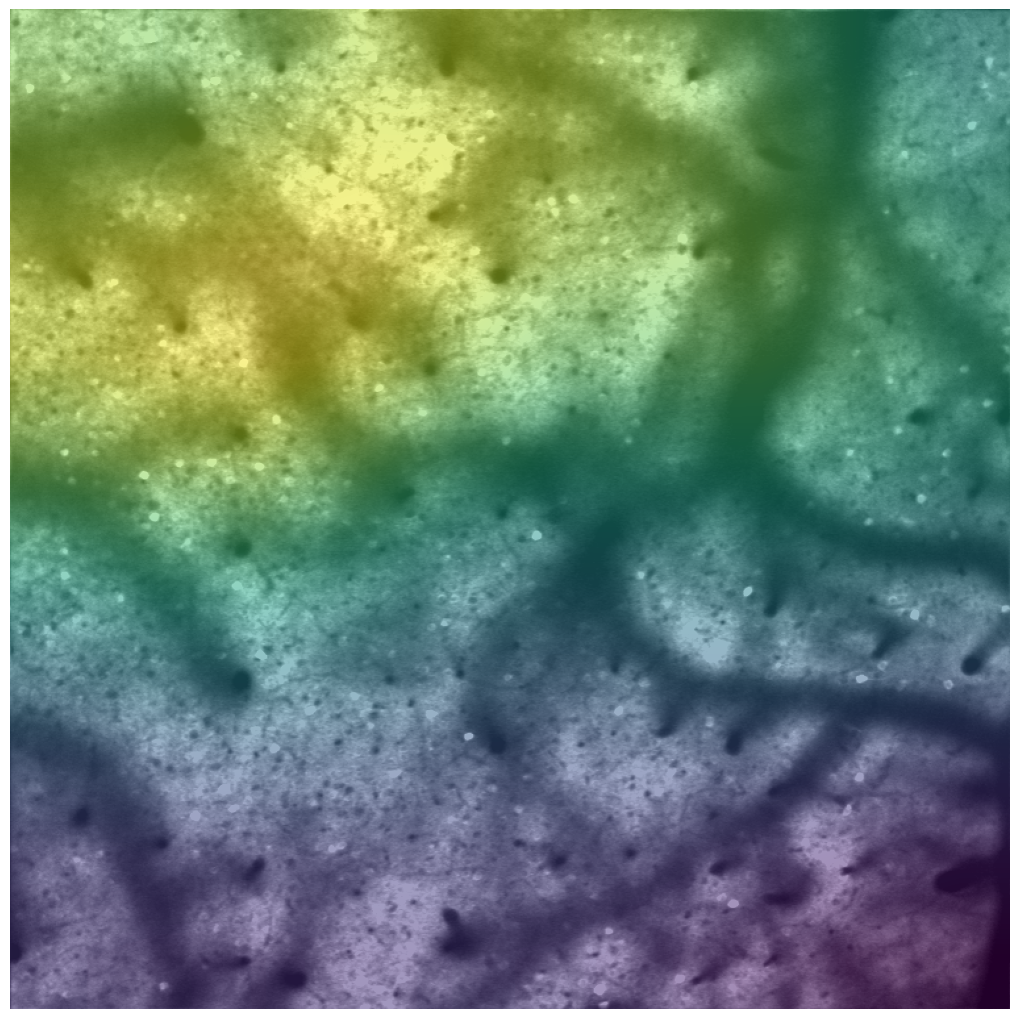

In [156]:
# Always plot all responsive cells
import scipy.ndimage as ndi
import cv2
cells_to_plot = Summ.L.suite2p_id

modulated=False

# Load the stat and ops files from the current folder
stat = np.load(Summ.L.activity_path + r'\stat.npy', allow_pickle=True)
ops = np.load(Summ.L.activity_path + r'\ops.npy', allow_pickle=True).item()

# Create two images - one for modulated and one for non-modulated cells
im_modulated = np.zeros((ops['Ly'], ops['Lx']))
im_non_modulated = np.zeros((ops['Ly'], ops['Lx']))

# Store cell centers for responsive cells
responsive_centers = []

for cell_id in cells_to_plot:
    # Find the index in suite2p
    idx = np.where(Summ.L.suite2p_id == cell_id)[0][0]

    ypix = stat[idx]['ypix'][~stat[idx]['overlap']]
    xpix = stat[idx]['xpix'][~stat[idx]['overlap']]

    # Calculate center of the cell
    center_y = np.mean(ypix)
    center_x = np.mean(xpix)

    if Summ.linear_stats[2]['responsive'][idx]:
        responsive_centers.append([center_x, center_y])

# Convert to numpy array for easier manipulation
responsive_centers = np.array(responsive_centers)

# Create a 2D histogram of cell centers
if len(responsive_centers) > 0:
    H, xedges, yedges = np.histogram2d(
        responsive_centers[:, 0], 
        responsive_centers[:, 1],
        bins=10,
        range=[[0, ops['Lx']], [0, ops['Ly']]]
    )
    
    # # Smooth the histogram using Gaussian filter
    H_smooth = ndi.gaussian_filter(H, sigma=1.5)
    
    # Normalize to 0-1 range
    H_smooth = (H_smooth - H_smooth.min()) / (H_smooth.max() - H_smooth.min())
    
    # Store in im_modulated
    im_modulated = H_smooth

# Create the figure for display
fig = plt.figure(figsize=(10, 10))

# # Plot non-modulated cells in orange first (so they appear behind)
# plt.imshow(im_modulated, alpha=1, vmin=0, vmax=1, cmap='viridis')

# resize im_modulated to match the shape of ops['refImg']
im_modulated = cv2.resize(im_modulated, (ops['refImg'].shape[1], ops['refImg'].shape[0]))

plt.imshow(im_modulated, alpha=1, cmap='viridis')
plt.imshow(ops['refImg'], alpha=0.5, cmap='gray', vmin=vmin, vmax=vmax)

plt.axis('off')  # Turn off axes
plt.tight_layout(pad=0)  # Remove padding

plt.show()

In [5]:
save_dir = data_dir + r'\dff_plots'

for stat in stats:
    
    result_dir = create_new_result_dir(save_dir, stat['condition'][0])
    
    # # find modulated cells
    modulated_cells = stat.loc[stat['modulated'] == True, 'cell_id'].values

    for cell_id in modulated_cells:
        fig = LinearPlots(L).plot_all_traces_colormap_distances(cell=cell_id, pre_time=3000, post_time=1000, conditions=conditions)
        fig.savefig(os.path.join(result_dir, f'cell_{cell_id}.png'))
        plt.close(fig)



Creating directory: monocular_no_history
Creating directory: monocular_history
Creating directory: binocular_no_history
Creating directory: binocular_history


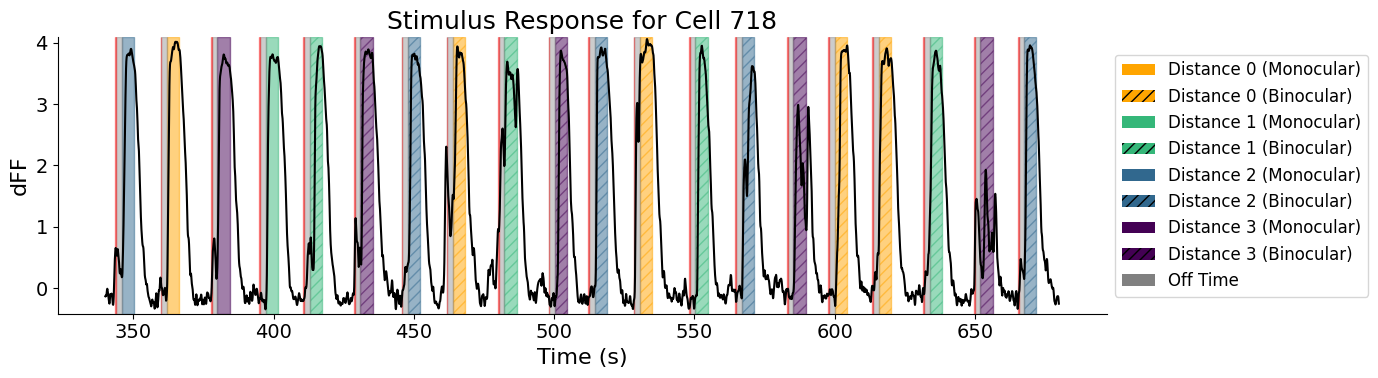

In [18]:
LinearPlots(L).plot_stimulus_response(repeats=[20,40], cell=718)

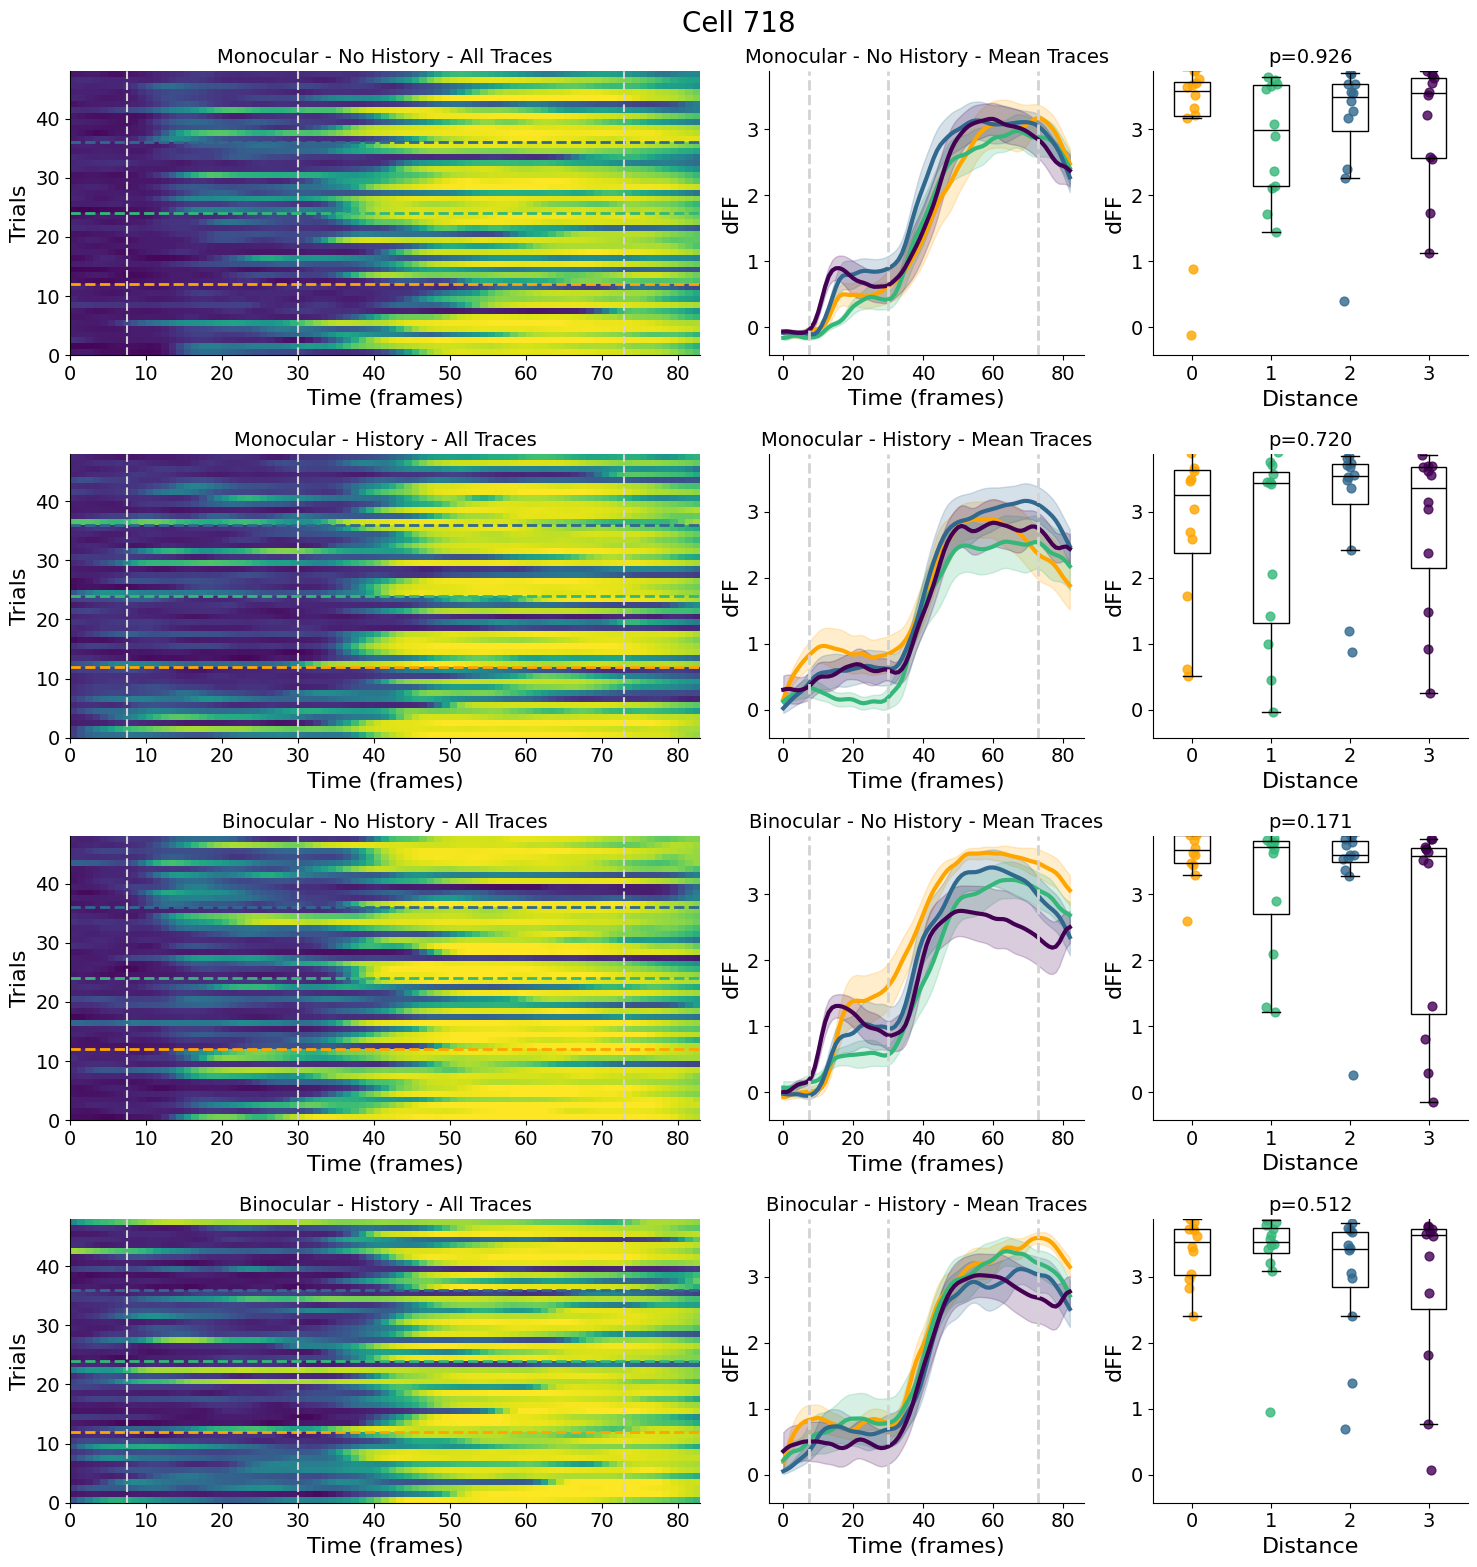

In [24]:
fig = LinearPlots(L).plot_all_traces_colormap_distances(cell=718, pre_time=3000, post_time=1000, conditions=conditions)


In [16]:
save_dir = data_dir + r'\dff_plots'
result_dir = create_new_result_dir(data_dir, 'non_modulated')
for cells in Summ.non_modulated_cells:
    fig = LinearPlots(L).plot_all_traces_colormap_distances(cell=cells, pre_time=3000, post_time=1000, conditions=conditions)
    fig.savefig(os.path.join(result_dir, f'cell_{cells}.png'))
    plt.close(fig)

Creating directory: non_modulated


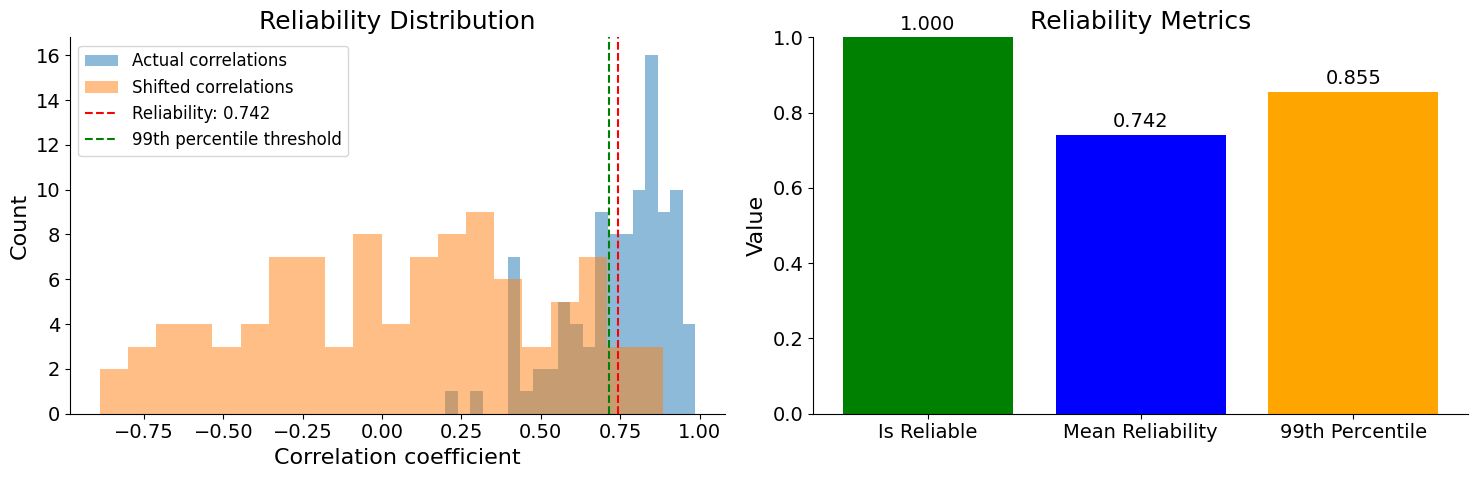

In [13]:
cell_id = 2699

is_reliable, reliability, corr_shifted, corr = L.analyze_cell_reliability(cell_id, n_iterations=100, distance=None, monocular=False, history=None)
# Create a figure to display reliability metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot reliability distribution
ax1.hist(corr, bins=20, alpha=0.5, label='Actual correlations')
ax1.hist(corr_shifted, bins=20, alpha=0.5, label='Shifted correlations')
ax1.axvline(reliability, color='r', linestyle='--', label=f'Reliability: {reliability:.3f}')
ax1.axvline(np.percentile(corr_shifted, 95), color='g', linestyle='--', 
            label='99th percentile threshold')
ax1.set_xlabel('Correlation coefficient')
ax1.set_ylabel('Count')
ax1.set_title('Reliability Distribution')
ax1.legend()

# Plot reliability metrics
metrics = ['Is Reliable', 'Mean Reliability', '99th Percentile']
values = [is_reliable, reliability, np.percentile(corr_shifted, 99)]
colors = ['green' if is_reliable else 'red', 'blue', 'orange']

ax2.bar(metrics, values, color=colors)
ax2.set_ylim(0, 1)
ax2.set_title('Reliability Metrics')
ax2.set_ylabel('Value')

# Add value labels on top of bars
for i, v in enumerate(values):
    ax2.text(i, v + 0.02, f'{v:.3f}', ha='center')

plt.tight_layout()
plt.show()



In [158]:
stats[0].head

<bound method NDFrame.head of       cell_id  responsive  modulated  modulated_p  mod_strength  \
0           0       False      False     0.370810      0.604264   
1           1       False      False     0.746041     -0.369241   
2           2       False      False     0.381621      0.427788   
3           3       False      False     0.317800      0.219822   
4           4       False      False     0.414012      0.461454   
...       ...         ...        ...          ...           ...   
4050     4954       False      False     0.515952      0.779888   
4051     4962       False      False     0.640393      0.059159   
4052     4963       False      False     0.030712      0.363281   
4053     4965       False      False     0.464456      0.102809   
4054     4966       False      False     0.670709      0.331516   

      pref_distance             condition  
0                 0  monocular_no_history  
1                 0  monocular_no_history  
2                 1  monocular_no

In [40]:
fig = Summ.plot_location_map('binocular_no_history', modulated=True)
plt.show()

In [39]:
# --- Step 1: Draw a polygon to define the “inside” mask (pop-up window) ---

import matplotlib
matplotlib.use('TkAgg') 
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path

# Load your data
stat = np.load(Summ.L.activity_path + r'\stat.npy', allow_pickle=True)
ops = np.load(Summ.L.activity_path + r'\ops.npy', allow_pickle=True).item()

# Compute display limits from meanImg (for better contrast)
mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

# Show the reference image and collect clicks with live lines
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(ops['refImg'], cmap='gray', vmin=vmin, vmax=vmax)
ax.set_title("Left-click to place vertices; press Enter when done.")

pts = []  # will store (x, y) clicks

def onclick(event):
    if event.inaxes != ax or event.button != 1:
        return
    x, y = event.xdata, event.ydata
    pts.append((x, y))
    ax.plot(x, y, 'ro')
    if len(pts) > 1:
        x0, y0 = pts[-2]
        ax.plot([x0, x], [y0, y], 'r-')
    fig.canvas.draw()

def onkey(event):
    if event.key == 'enter':
        if len(pts) >= 3:
            x0, y0 = pts[0]
            x_last, y_last = pts[-1]
            ax.plot([x_last, x0], [y_last, y0], 'r-')
            fig.canvas.draw()
        plt.close(fig)

cid_click = fig.canvas.mpl_connect('button_press_event', onclick)
cid_key   = fig.canvas.mpl_connect('key_press_event', onkey)
plt.show()

if len(pts) < 3:
    raise RuntimeError(f"Need at least 3 vertices; got {len(pts)}.")

# Build a Boolean mask of “inside‐polygon” pixels
Ly, Lx = ops['Ly'], ops['Lx']
x_coords, y_coords = np.meshgrid(np.arange(Lx), np.arange(Ly))
all_points = np.vstack((x_coords.flatten(), y_coords.flatten())).T  # shape = (Lx*Ly, 2)
poly_path = Path(pts)
inside_flat = poly_path.contains_points(all_points)
mask = inside_flat.reshape((Ly, Lx))  # True = inside, False = outside

# --- Step 2: Plot only cells whose center falls inside “mask” ---

# Always plot all responsive cells
cells_to_plot = Summ.responsive_cells['binocular_no_history']
# 

# Prepare two blank images for “inside” plotting
im_modulated_inside    = np.zeros((Ly, Lx), dtype=float)
im_non_modulated_inside = np.zeros((Ly, Lx), dtype=float)

count_inside = 0
count_modulated_inside = 0
condition = 'binocular_no_history'

for cell_id in cells_to_plot:
    # Find index in suite2p (same as your original code)
    idx = np.where(Summ.L.suite2p_id == cell_id)[0][0]
    ypix = stat[idx]['ypix'][~stat[idx]['overlap']]
    xpix = stat[idx]['xpix'][~stat[idx]['overlap']]
    center_y = np.mean(ypix)
    center_x = np.mean(xpix)

    modulated = True
    
    # Check if the cell center rounds to a pixel inside the polygon
    iy = int(round(center_y))
    ix = int(round(center_x))
    if iy < 0 or iy >= Ly or ix < 0 or ix >= Lx:
        continue
    if not mask[iy, ix]:
        continue
    
    # This cell is inside
    count_inside += 1
    
    # Build a circular footprint (radius=5) around the center
    y_grid, x_grid = np.ogrid[:Ly, :Lx]
    dist = np.sqrt((x_grid - center_x)**2 + (y_grid - center_y)**2)
    circle_mask = dist <= 5
    
    # Plot into either modulated‐inside or non‐modulated‐inside
    if modulated and (cell_id in Summ.modulated_cells[condition]):
        im_modulated_inside[circle_mask] = 0.8
        count_modulated_inside += 1
    else:
        im_non_modulated_inside[circle_mask] = 0.1

# Now display a figure of “only inside” cells:
fig1 = plt.figure(figsize=(10, 10))
plt.imshow(ops['refImg'], alpha=0.5, cmap='gray', vmin=vmin, vmax=vmax)

masked_non = np.ma.masked_where(im_non_modulated_inside == 0, im_non_modulated_inside)
masked_mod   = np.ma.masked_where(im_modulated_inside == 0,    im_modulated_inside)

plt.imshow(masked_non, alpha=1, vmin=0, vmax=1, cmap='viridis')
plt.imshow(masked_mod,   alpha=1, vmin=0, vmax=1, cmap='viridis')

plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

# --- Step 3: Another figure summarizing counts of cells inside vs. modulated inside ---

import matplotlib.pyplot as plt

labels = ['Total inside', 'Modulated inside']
values = [count_inside, count_modulated_inside]

fig2, ax2 = plt.subplots(figsize=(5, 4))
bars = ax2.bar(labels, values, color=['#4C72B0', '#55A868'])
ax2.set_ylabel('Cell count')
ax2.set_title('Cells within drawn polygon')

# Calculate percentages
total = values[0]
percentages = [100, (values[1]/total)*100]

for bar, value, pct in zip(bars, values, percentages):
    height = bar.get_height()
    # Add count and percentage to bar label
    label = f'{int(value)} ({pct:.1f}%)'
    ax2.text(bar.get_x() + bar.get_width()/2, height + 1, label,
             ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(f"Number of responsive cells inside polygon: {count_inside}")
print(f"   of which modulated: {count_modulated_inside} ({percentages[1]:.1f}%)")

Number of responsive cells inside polygon: 201
   of which modulated: 45 (22.4%)


In [4]:
# --- Full cell: draw a polygon in a popup window and get a Boolean mask ---

# 1. Force Matplotlib to use TkAgg so that a separate window is created.
import matplotlib
matplotlib.use('TkAgg')   # switch backend before pyplot is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import PolygonSelector
from matplotlib.path import Path

# 2. Load your data (adjust the paths if needed)
stat = np.load(Summ.L.activity_path + r'\stat.npy', allow_pickle=True)
ops = np.load(Summ.L.activity_path + r'\ops.npy', allow_pickle=True).item()

# 3. Compute display limits from meanImg
mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

# 4. Create a popup figure and show the reference image
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(ops['refImg'], cmap='gray', vmin=vmin, vmax=vmax)
ax.set_title("Click to place vertices; double-click to close")

# 5. Prepare storage for the mask and vertices
Ly, Lx = ops['Ly'], ops['Lx']
mask = np.zeros((Ly, Lx), dtype=bool)
vertices = None

# 6. Define the callback that runs when the polygon is closed
def onselect(verts):
    global vertices, mask
    vertices = verts
    path = Path(vertices)

    # Build a grid of pixel centers
    ny, nx = Ly, Lx
    x_coords, y_coords = np.meshgrid(np.arange(nx), np.arange(ny))
    all_points = np.vstack((x_coords.flatten(), y_coords.flatten())).T  # shape = (nx*ny, 2)

    # Determine which points lie inside the polygon
    inside = path.contains_points(all_points)
    mask = inside.reshape((ny, nx))

    # Overlay the mask onto the image in a semi-transparent color
    ax.imshow(
        np.ma.masked_where(~mask, mask),
        cmap='spring',
        alpha=0.5,
        origin='upper'
    )
    fig.canvas.draw_idle()

# 7. Instantiate PolygonSelector on this popup window
selector = PolygonSelector(
    ax,
    onselect,
    useblit=True,
    props=dict(color='r', linewidth=2, linestyle='--'),
    handle_props=dict(marker='o', markersize=5, markerfacecolor='r', markeredgecolor='r')
)

# 8. Show the window (blocking). Once you double-click to close the polygon,
#    the callback ‘onselect’ will run, filling in the global `mask`.
plt.show()

# --- After closing the polygon: `mask` is a (Ly, Lx) Boolean array ---
# True = pixel inside your drawn polygon, False = outside.

# Example: create two images based on that mask
im_modulated = np.zeros((Ly, Lx), dtype=float)
im_non_modulated = np.zeros((Ly, Lx), dtype=float)
im_modulated[mask] = 1.0
im_non_modulated[~mask] = 1.0

print("Finished drawing. Polygon vertices:", vertices)
print("Mask shape:", mask.shape, "| Number of inside pixels:", mask.sum())


Finished drawing. Polygon vertices: [(np.float64(728.6558441558442), np.float64(284.5)), (np.float64(605.2792207792209), np.float64(684.2402597402597)), (np.float64(83.3961038961039), np.float64(747.1623376623377)), (np.float64(10.603896103896105), np.float64(576.9025974025974)), (np.float64(3.201298701298711), np.float64(9.370129870129745)), (np.float64(718.7857142857143), np.float64(16.772727272727252))]
Mask shape: (760, 760) | Number of inside pixels: 472791


In [5]:
# --- Full cell: draw a polygon in a popup window and get a Boolean mask ---

# 1. Force Matplotlib to use TkAgg so that a separate window is created.
import matplotlib
matplotlib.use('TkAgg')   # switch backend before pyplot is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import PolygonSelector
from matplotlib.path import Path

# 2. Load your data (adjust the paths if needed)
stat = np.load(Summ.L.activity_path + r'\stat.npy', allow_pickle=True)
ops = np.load(Summ.L.activity_path + r'\ops.npy', allow_pickle=True).item()

# 3. Compute display limits from meanImg
mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

# 4. Create a popup figure and show the reference image
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(ops['refImg'], cmap='gray', vmin=vmin, vmax=vmax)
ax.set_title("Click to place vertices; double-click to close")

# 5. Prepare storage for the mask and vertices
Ly, Lx = ops['Ly'], ops['Lx']
mask = np.zeros((Ly, Lx), dtype=bool)
vertices = None

# 6. Define the callback that runs when the polygon is closed
def onselect(verts):
    global vertices, mask
    vertices = verts
    path = Path(vertices)

    # Build a grid of pixel centers
    ny, nx = Ly, Lx
    x_coords, y_coords = np.meshgrid(np.arange(nx), np.arange(ny))
    all_points = np.vstack((x_coords.flatten(), y_coords.flatten())).T  # shape = (nx*ny, 2)

    # Determine which points lie inside the polygon
    inside = path.contains_points(all_points)
    mask = inside.reshape((ny, nx))

    # Overlay the mask onto the image in a semi-transparent color
    ax.imshow(
        np.ma.masked_where(~mask, mask),
        cmap='spring',
        alpha=0.5,
        origin='upper'
    )
    fig.canvas.draw_idle()

# 7. Instantiate PolygonSelector on this popup window
selector = PolygonSelector(
    ax,
    onselect,
    useblit=True,
    props=dict(color='r', linewidth=2, linestyle='--'),
    handle_props=dict(marker='o', markersize=5, markerfacecolor='r', markeredgecolor='r')
)

# 8. Show the window (blocking). Once you double-click to close the polygon,
#    the callback ‘onselect’ will run, filling in the global `mask`.
plt.show()

# --- After closing the polygon: `mask` is a (Ly, Lx) Boolean array ---
# True = pixel inside your drawn polygon, False = outside.

# Example: create two images based on that mask
im_modulated = np.zeros((Ly, Lx), dtype=float)
im_non_modulated = np.zeros((Ly, Lx), dtype=float)
im_modulated[mask] = 1.0
im_non_modulated[~mask] = 1.0

print("Finished drawing. Polygon vertices:", vertices)
print("Mask shape:", mask.shape, "| Number of inside pixels:", mask.sum())


Finished drawing. Polygon vertices: [(np.float64(718.7857142857143), np.float64(88.33116883116872)), (np.float64(718.7857142857143), np.float64(88.33116883116872)), (np.float64(658.331168831169), np.float64(541.1233766233765)), (np.float64(658.331168831169), np.float64(541.1233766233765)), (np.float64(199.37012987012986), np.float64(707.6818181818181)), (np.float64(26.642857142857153), np.float64(478.20129870129864)), (np.float64(25.40909090909092), np.float64(14.305194805194787))]
Mask shape: (760, 760) | Number of inside pixels: 372745


Button(description='Finish Drawing', style=ButtonStyle())

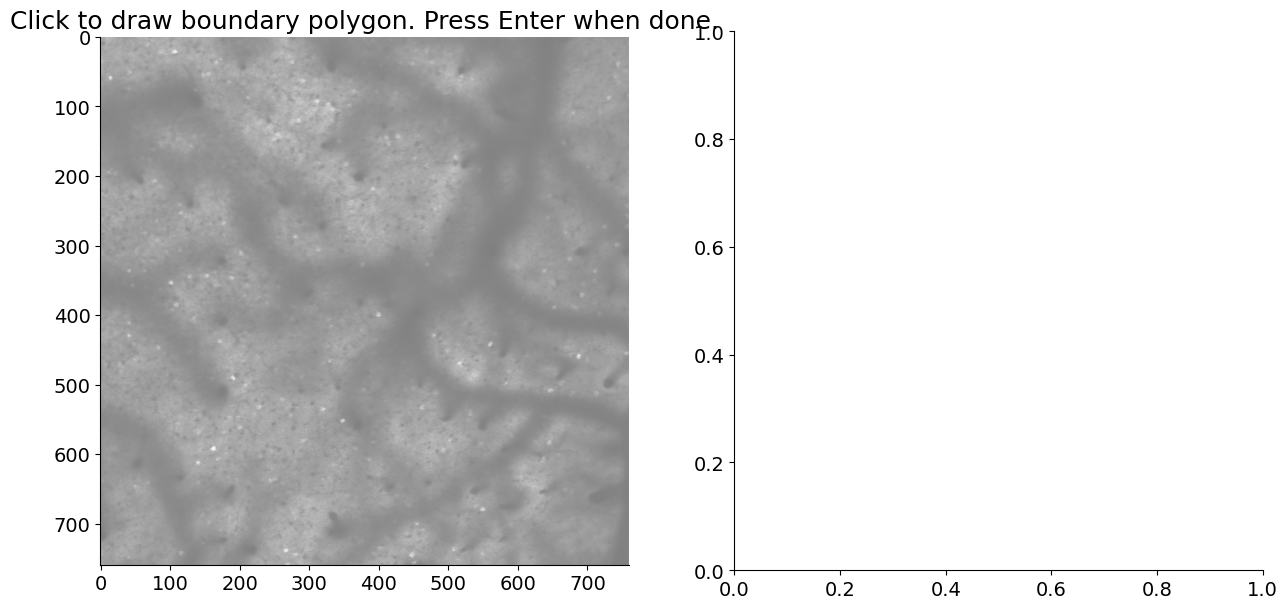

ValueError: 'vertices' must be 2D with shape (N, 2), but your input has shape (0,)

In [ ]:
fig = plot_location_map(Summ, 'binocular_no_history', modulated=True)

In [87]:
from scipy.optimize import curve_fit

directory = create_new_result_dir(data_dir, 'responsive_cells')
responsive_cells = Summ.responsive_cells
print(responsive_cells)

# Create figure
plt.figure(figsize=(10, 6))

def gaussian(x, a, mu, sigma, baseline):
    return a * np.exp(-((x - mu)**2) / (2 * sigma**2)) + baseline

# Fit and plot for each cell
for cell in responsive_cells:
    mean_trace = L.get_all_traces(cell, distance=None, mean_trace=True, monocular=None, history=None)[0]
    x = np.arange(len(mean_trace))
    try:
        p0 = [np.max(mean_trace) - np.min(mean_trace), np.argmax(mean_trace), 5, np.min(mean_trace)]
        popt, _ = curve_fit(gaussian, x, mean_trace, p0=p0)
        a, mu, sigma, baseline = popt
        
        # Calculate R-squared
        y_fit = gaussian(x, a, mu, sigma, baseline)
        residuals = mean_trace - y_fit
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((mean_trace - np.mean(mean_trace))**2)
        r_squared = 1 - (ss_res / ss_tot)

        # Create figure and set up plot
        fig = plt.figure()
        plt.title(f'Cell {cell} (R²={r_squared:.2f})')
        plt.xlabel('Time (frames)')
        plt.ylabel('Response')

        # Plot data and fit
        plt.plot(mean_trace, alpha=0.8, label=f'Cell {cell} (R²={r_squared:.2f})')
        plt.plot(y_fit, '--', alpha=0.8)

        # Add legend and adjust layout
        plt.tight_layout()
        
        # Save and close figure
        fig.savefig(os.path.join(directory, f'cell_{cell}_gaussian.png'))
        plt.close()
        
    except RuntimeError:
        continue

    

Directory responsive_cells already exists
[   2   10   19   37   40   44   45   52   87   95  110  117  119  130
  131  142  146  161  177  179  181  190  191  193  209  217  229  237
  242  248  255  261  267  287  290  297  321  322  324  326  331  336
  338  354  361  366  368  371  376  379  381  383  384  391  398  399
  400  404  413  417  429  431  433  434  442  459  477  478  479  480
  486  499  501  502  511  525  533  540  548  559  562  568  571  573
  584  587  606  616  629  652  654  656  657  659  662  663  669  672
  675  676  684  692  697  705  710  715  716  717  732  739  740  748
  750  751  753  757  761  775  776  777  779  780  782  789  793  795
  797  799  801  804  806  807  810  812  817  819  832  846  847  848
  856  858  863  865  873  882  883  901  902  904  906  908  909  911
  912  913  920  923  936  943  946  948  951  956  964  984  992  994
  997 1002 1008 1014 1022 1023 1026 1028 1035 1037 1042 1045 1049 1056
 1057 1068 1069 1073 1074 1076 1081

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_14084\3158154666.py:19: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(gaussian, x, mean_trace, p0=p0)


<Figure size 1000x600 with 0 Axes>

In [84]:
responsive_cells = Summ.responsive_cells
directory = create_new_result_dir(data_dir, 'responsive_cells')

for cell in responsive_cells:
    fig = LinearPlots(L).plot_all_traces_colormap(cell=cell)
    fig.savefig(os.path.join(directory, f'cell_{cell}.png'))
    plt.close(fig)

Directory responsive_cells already exists
